# Banknote Authentication — Decision Trees & Support Vector Machines
## Name: Puranik Aryan hitesh
## student id : 202618030

**Dataset:** [UCI Banknote Authentication](https://archive.ics.uci.edu/dataset/267/banknote+authentication) (1,372 samples, four numerical features, binary class).  
**Reproducibility:** fixed random seed 42; identical stratified splits for fair comparisons.  
**From scratch:** NumPy/Pandas only for tree fitting and inference. Scikit-learn is used for splitting, evaluation and benchmark models.


## Part A — Decision Tree from Scratch

### A1. Environment and imports

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dataclasses import dataclass
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid')
FEATURES = ['variance', 'skewness', 'curtosis', 'entropy']
print('Environment ready')

Environment ready


### A2. Load dataset

UCI describes these as wavelet-image statistics. `entropy` here is a **predictor**; it is distinct from entropy used as a **tree impurity criterion**. 

In [2]:
df = pd.read_csv(r"D:\ml_environment\data\data_banknote_authentication.txt", header=None, names=FEATURES + ['class'])
df

,variance,skewness,curtosis,entropy,class
0,3.62160,8.66610,-2.8073,-0.44699,0
1,4.54590,8.16740,-2.4586,-1.46210,0
2,3.86600,-2.63830,1.9242,0.10645,0
3,3.45660,9.52280,-4.0112,-3.59440,0
4,0.32924,-4.45520,4.5718,-0.98880,0
...,...,...,...,...,...
1367,0.40614,1.34920,-1.4501,-0.55949,1
1368,-1.38870,-4.87730,6.4774,0.34179,1
1369,-3.75030,-13.45860,17.5932,-2.77710,1
1370,-3.56370,-8.38270,12.3930,-1.28230,1


### A3. Exploratory analysis

,count,mean,std,min,25%,50%,75%,max
variance,1372.0,0.433735,2.842763,-7.0421,-1.773000,0.49618,2.821475,6.8248
skewness,1372.0,1.922353,5.869047,-13.7731,-1.708200,2.31965,6.814625,12.9516
curtosis,1372.0,1.397627,4.310030,-5.2861,-1.574975,0.61663,3.179250,17.9274
entropy,1372.0,-1.191657,2.101013,-8.5482,-2.413450,-0.58665,0.394810,2.4495
class,1372.0,0.444606,0.497103,0.0000,0.000000,0.00000,1.000000,1.0000


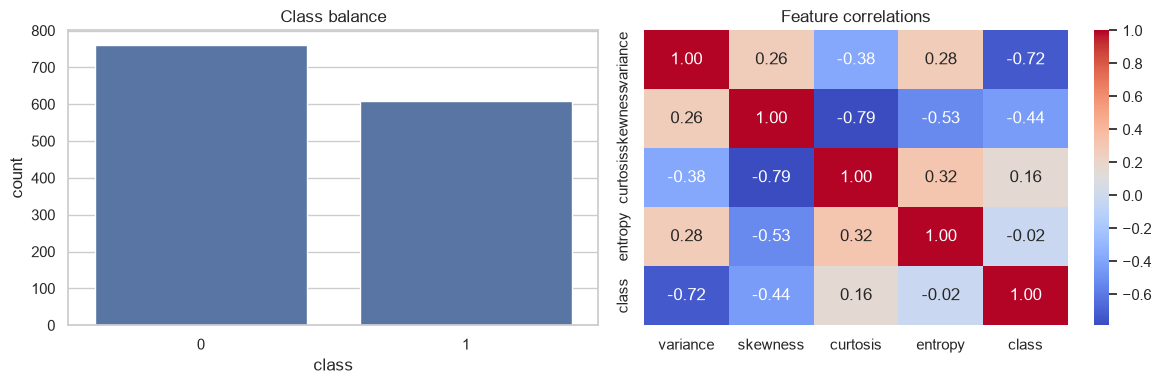

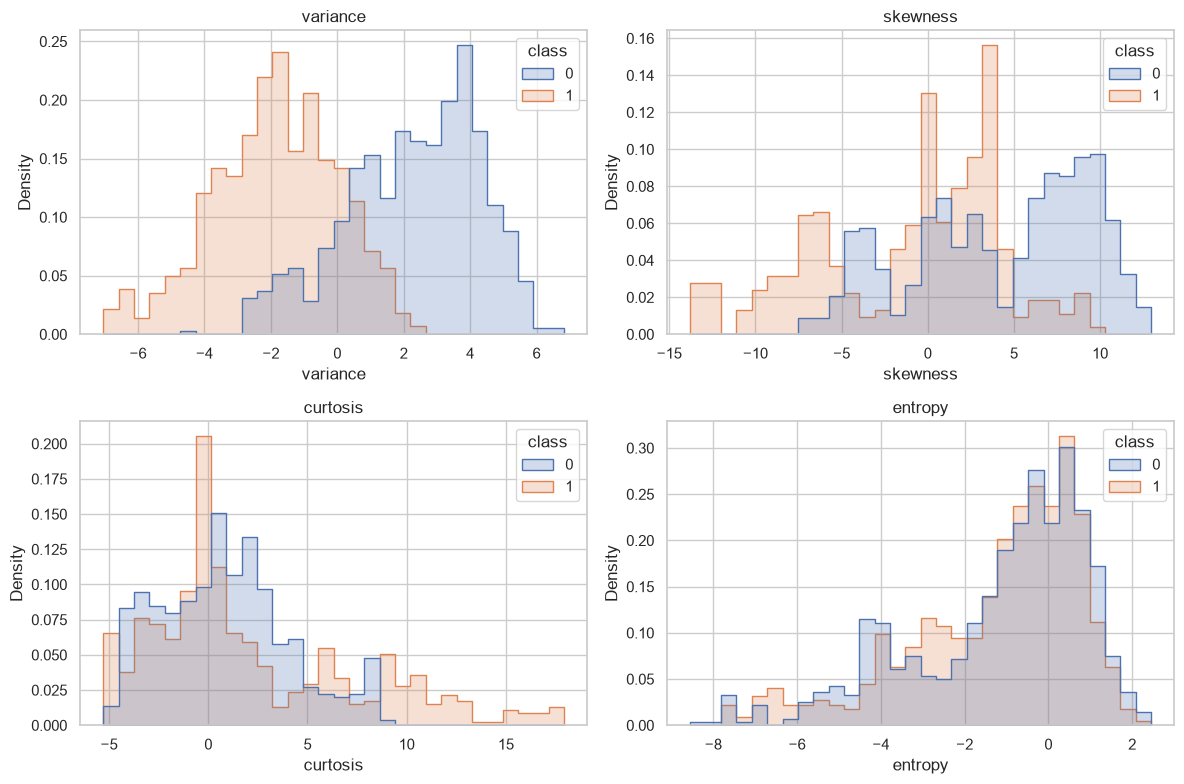

In [3]:
display(df.describe().T)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x='class', ax=axes[0]); axes[0].set_title('Class balance')
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1]); axes[1].set_title('Feature correlations')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, feature in zip(axes.flat, FEATURES):
    sns.histplot(data=df, x=feature, hue='class', bins=30, stat='density', common_norm=False, element='step', ax=ax)
    ax.set_title(feature)
plt.tight_layout(); plt.show()

### A4. Train/test split

Split **before training**. Use all four features for performance comparison, and a **separate two-feature model** (variance, skewness) for meaningful 2D decision boundaries. A tree requires no standardization.

In [4]:
X = df[FEATURES].to_numpy(dtype=float)
y = df['class'].to_numpy(dtype=int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train_2d, X_test_2d = X_train[:, :2], X_test[:, :2]
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Train classes:', np.bincount(y_train), 'Test classes:', np.bincount(y_test))

Train: (1097, 4) Test: (275, 4)
Train classes: [609 488] Test classes: [153 122]


### A5. Mathematical foundation

For class probabilities $p_k$:

$$Gini(D)=1-\sum_{k=1}^K p_k^2$$

$$Entropy(D)=-\sum_{k=1}^K p_k\log_2(p_k),\qquad 0\log_2 0 := 0$$

For a split into left and right partitions:

$$I_{split}=\frac{n_L}{n}I(D_L)+\frac{n_R}{n}I(D_R)$$

$$Gain = I(D)-I_{split}$$

For continuous variables, consider midpoint thresholds between consecutive **distinct sorted feature values**. At each node, choose the feature/threshold with maximum impurity reduction. Repeat recursively until pure or constrained by `max_depth`, `min_samples_split`, `min_samples_leaf`, or `min_impurity_decrease`. Each leaf predicts its majority class.


### A6. Impurity functions (NumPy implementation)

In [5]:
def gini_impurity(y):
    y = np.asarray(y)
    if y.size == 0: return 0.0
    _, counts = np.unique(y, return_counts=True)
    p = counts / counts.sum()
    return float(1.0 - np.sum(p ** 2))

def entropy_impurity(y):
    y = np.asarray(y)
    if y.size == 0: return 0.0
    _, counts = np.unique(y, return_counts=True)
    p = counts / counts.sum()
    return float(-np.sum(p * np.log2(p)))

assert np.isclose(gini_impurity([0, 0, 1, 1]), 0.5)
assert np.isclose(entropy_impurity([0, 0, 1, 1]), 1.0)
assert gini_impurity([1, 1, 1]) == 0
assert entropy_impurity([1, 1, 1]) == 0
print('Impurity tests passed')

Impurity tests passed


### A7. Recursive Decision Tree implementation

In [6]:
@dataclass
class TreeNode:
    prediction: int
    n_samples: int
    impurity: float
    counts: tuple
    feature: int = None
    threshold: float = None
    gain: float = 0.0
    left: object = None
    right: object = None

    @property
    def is_leaf(self):
        return self.feature is None

class ManualDecisionTree:
    def __init__(self, criterion='gini', max_depth=None, min_samples_split=2,
                 min_samples_leaf=1, min_impurity_decrease=0.0):
        if criterion not in ('gini', 'entropy'):
            raise ValueError('criterion must be gini or entropy')
        if max_depth is not None and max_depth < 0: raise ValueError('max_depth must be >= 0')
        if min_samples_split < 2 or min_samples_leaf < 1: raise ValueError('Invalid sample limits')
        if min_impurity_decrease < 0: raise ValueError('min_impurity_decrease must be nonnegative')
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_impurity_decrease = min_impurity_decrease
        self._impurity = gini_impurity if criterion == 'gini' else entropy_impurity

    def _best_split(self, X, y, parent_impurity):
        n, n_features = X.shape
        best_feature, best_threshold, best_gain = None, None, 0.0
        for feature in range(n_features):
            order = np.argsort(X[:, feature], kind='mergesort')
            values, labels = X[order, feature], y[order]
            candidate_positions = np.flatnonzero(values[:-1] < values[1:]) + 1
            for pos in candidate_positions:
                if pos < self.min_samples_leaf or n - pos < self.min_samples_leaf:
                    continue
                left_y, right_y = labels[:pos], labels[pos:]
                weighted = (pos * self._impurity(left_y) + (n-pos) * self._impurity(right_y)) / n
                gain = parent_impurity - weighted
                if gain > best_gain + 1e-12:
                    best_feature = feature
                    # Stable midpoint, avoids overflow for large values
                    best_threshold = float(values[pos-1] + (values[pos] - values[pos-1]) / 2)
                    best_gain = float(gain)
        return best_feature, best_threshold, best_gain

    def _build(self, X, y, depth):
        counts = np.bincount(y, minlength=self.n_classes_)
        prediction = int(np.argmax(counts))
        impurity = self._impurity(y)
        node = TreeNode(prediction=prediction, n_samples=len(y), impurity=impurity, counts=tuple(counts))
        stop = (impurity <= 1e-12 or len(y) < self.min_samples_split or
                len(y) < 2 * self.min_samples_leaf or
                (self.max_depth is not None and depth >= self.max_depth))
        if stop: return node
        feature, threshold, gain = self._best_split(X, y, impurity)
        if feature is None or gain <= 1e-12 or gain + 1e-12 < self.min_impurity_decrease:
            return node
        mask = X[:, feature] <= threshold
        node.feature, node.threshold, node.gain = feature, threshold, gain
        node.left = self._build(X[mask], y[mask], depth + 1)
        node.right = self._build(X[~mask], y[~mask], depth + 1)
        return node

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y)
        if X.ndim != 2 or y.ndim != 1 or len(X) != len(y) or len(y) == 0:
            raise ValueError('Expected nonempty 2D X and matching 1D y')
        if not np.isfinite(X).all(): raise ValueError('X must be finite')
        self.classes_, encoded = np.unique(y, return_inverse=True)
        self.n_classes_ = len(self.classes_)
        self.n_features_in_ = X.shape[1]
        self.root_ = self._build(X, encoded, depth=0)
        return self

    def _predict_one_encoded(self, x):
        node = self.root_
        while not node.is_leaf:
            node = node.left if x[node.feature] <= node.threshold else node.right
        return node.prediction

    def predict(self, X):
        if not hasattr(self, 'root_'): raise RuntimeError('Call fit first')
        X = np.asarray(X, dtype=float)
        if X.ndim == 1: X = X.reshape(1, -1)
        if X.ndim != 2 or X.shape[1] != self.n_features_in_:
            raise ValueError('Incorrect number of features')
        return self.classes_[np.array([self._predict_one_encoded(row) for row in X], dtype=int)]

    def get_depth(self):
        def walk(node): return 0 if node.is_leaf else 1 + max(walk(node.left), walk(node.right))
        return walk(self.root_)

    def get_n_leaves(self):
        def walk(node): return 1 if node.is_leaf else walk(node.left) + walk(node.right)
        return walk(self.root_)

    def print_rules(self, feature_names=None, max_print_depth=None):
        feature_names = feature_names or [f'x{i}' for i in range(self.n_features_in_)]
        def walk(node, depth):
            indent = '  ' * depth
            if node.is_leaf:
                print(f'{indent}Predict {self.classes_[node.prediction]} | n={node.n_samples}, impurity={node.impurity:.4f}, counts={node.counts}')
            elif max_print_depth is not None and depth >= max_print_depth:
                print(f'{indent}... [subtree omitted; n={node.n_samples}]')
            else:
                print(f'{indent}IF {feature_names[node.feature]} <= {node.threshold:.5f} (gain={node.gain:.5f}, n={node.n_samples}):')
                walk(node.left, depth + 1)
                print(f'{indent}ELSE ({feature_names[node.feature]} > {node.threshold:.5f}):')
                walk(node.right, depth + 1)
        walk(self.root_, 0)

### A8. Unit tests on controlled synthetic data

In [7]:
toy_X = np.array([[0.0], [1.0], [2.0], [3.0], [4.0], [5.0]])
toy_y = np.array([0, 0, 0, 1, 1, 1])
for criterion in ('gini', 'entropy'):
    toy_tree = ManualDecisionTree(criterion=criterion, max_depth=2).fit(toy_X, toy_y)
    assert np.array_equal(toy_tree.predict(toy_X), toy_y)
    assert toy_tree.root_.feature == 0
    assert np.isclose(toy_tree.root_.threshold, 2.5)
assert ManualDecisionTree(max_depth=0).fit(toy_X, toy_y).get_depth() == 0
assert ManualDecisionTree(min_samples_leaf=4).fit(toy_X, toy_y).get_n_leaves() == 1
print('All synthetic tests passed')

All synthetic tests passed


### A9. Train manual and Scikit-learn trees on all four features

In [8]:
criterion = 'gini'
max_depth = 5
manual_tree = ManualDecisionTree(criterion=criterion, max_depth=max_depth).fit(X_train, y_train)
sklearn_tree = DecisionTreeClassifier(criterion=criterion, max_depth=max_depth, random_state=SEED).fit(X_train, y_train)
print('Manual depth/leaves:', manual_tree.get_depth(), manual_tree.get_n_leaves())
print('Sklearn depth/leaves:', sklearn_tree.get_depth(), sklearn_tree.get_n_leaves())
print('\nManual learned rules (first 3 levels):')
manual_tree.print_rules(FEATURES, max_print_depth=3)

Manual depth/leaves: 5 20
Sklearn depth/leaves: 5 20

Manual learned rules (first 3 levels):
IF variance <= 0.76510 (gain=0.24209, n=1097):
  IF skewness <= 5.16080 (gain=0.14893, n=593):
    IF variance <= 0.32016 (gain=0.02869, n=464):
      ... [subtree omitted; n=413]
    ELSE (variance > 0.32016):
      ... [subtree omitted; n=51]
  ELSE (skewness > 5.16080):
    IF variance <= -3.43110 (gain=0.34269, n=129):
      ... [subtree omitted; n=32]
    ELSE (variance > -3.43110):
      ... [subtree omitted; n=97]
ELSE (variance > 0.76510):
  IF curtosis <= -4.45585 (gain=0.03590, n=504):
    IF variance <= 3.30405 (gain=0.44444, n=24):
      Predict 1 | n=16, impurity=0.0000, counts=(np.int64(0), np.int64(16))
    ELSE (variance > 3.30405):
      Predict 0 | n=8, impurity=0.0000, counts=(np.int64(8), np.int64(0))
  ELSE (curtosis > -4.45585):
    IF variance <= 1.74385 (gain=0.00834, n=480):
      ... [subtree omitted; n=96]
    ELSE (variance > 1.74385):
      ... [subtree omitted; n=3

### A10. Evaluation and prediction agreement

,model,accuracy,precision,recall,f1
0,Manual Tree (4D),0.9927,0.9839,1.0,0.9919
1,Sklearn Tree (4D),0.9927,0.9839,1.0,0.9919


Prediction agreement: 100.00%
Manual tree classification report:
               precision    recall  f1-score   support

           0       1.00      0.99      0.99       153
           1       0.98      1.00      0.99       122

    accuracy                           0.99       275
   macro avg       0.99      0.99      0.99       275
weighted avg       0.99      0.99      0.99       275



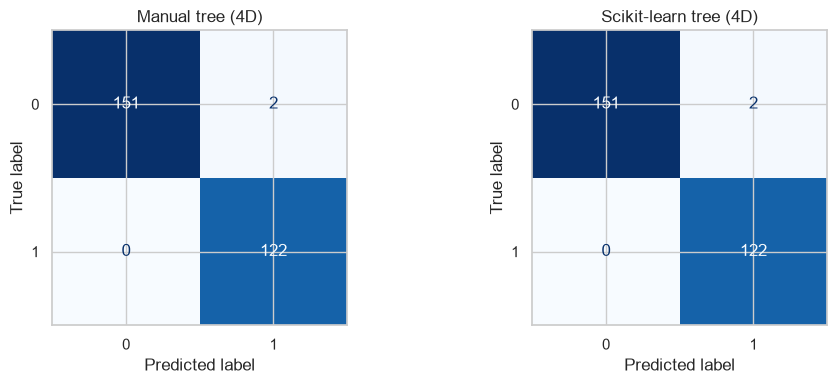

In [9]:
def metric_row(name, y_true, y_pred):
    return dict(model=name, accuracy=accuracy_score(y_true, y_pred),
                precision=precision_score(y_true, y_pred, zero_division=0),
                recall=recall_score(y_true, y_pred, zero_division=0),
                f1=f1_score(y_true, y_pred, zero_division=0))

pred_manual = manual_tree.predict(X_test)
pred_sklearn = sklearn_tree.predict(X_test)
comparison = pd.DataFrame([metric_row('Manual Tree (4D)', y_test, pred_manual),
                           metric_row('Sklearn Tree (4D)', y_test, pred_sklearn)])
display(comparison.round(4))
print(f'Prediction agreement: {np.mean(pred_manual == pred_sklearn):.2%}')
print('Manual tree classification report:\n', classification_report(y_test, pred_manual, zero_division=0))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, title in zip(axes, [pred_manual, pred_sklearn], ['Manual tree (4D)', 'Scikit-learn tree (4D)']):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(title)
plt.tight_layout(); plt.show()

### A11. 2D decision boundaries — variance and skewness

**Important:** These are separately fitted two-feature models. Their metrics must not be confused with the four-feature models above. Both boundaries use the same test set and grid.

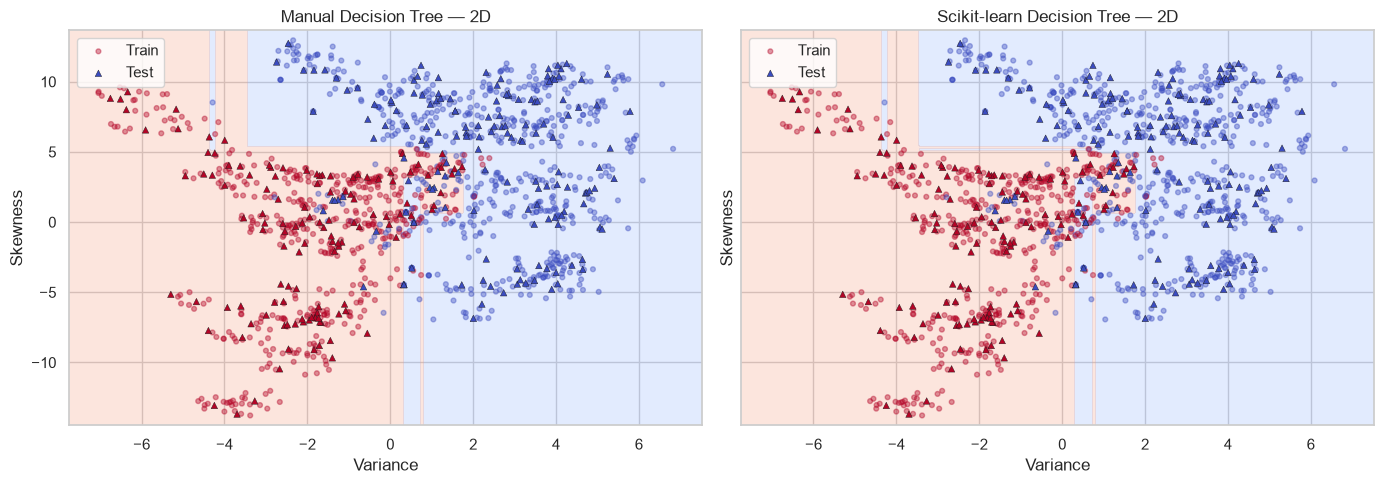

,model,accuracy,precision,recall,f1
0,Manual Tree (2D),0.9309,0.8815,0.9754,0.9261
1,Sklearn Tree (2D),0.9309,0.8815,0.9754,0.9261


In [10]:
manual_2d = ManualDecisionTree(criterion='gini', max_depth=5).fit(X_train_2d, y_train)
sklearn_2d = DecisionTreeClassifier(criterion='gini', max_depth=5, random_state=SEED).fit(X_train_2d, y_train)

def plot_decision_boundary(ax, model, X_train_plot, y_train_plot, X_test_plot, y_test_plot, title, resolution=220):
    all_x = np.vstack([X_train_plot, X_test_plot])
    x_min, x_max = all_x[:, 0].min() - 0.7, all_x[:, 0].max() + 0.7
    y_min, y_max = all_x[:, 1].min() - 0.7, all_x[:, 1].max() + 0.7
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, resolution), np.linspace(y_min, y_max, resolution))
    mesh = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(mesh).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], cmap='coolwarm', alpha=0.25)
    ax.scatter(X_train_plot[:, 0], X_train_plot[:, 1], c=y_train_plot, cmap='coolwarm', s=12, alpha=0.40, marker='o', label='Train')
    ax.scatter(X_test_plot[:, 0], X_test_plot[:, 1], c=y_test_plot, cmap='coolwarm', s=22, edgecolor='k', linewidth=0.3, marker='^', label='Test')
    ax.set(xlabel='Variance', ylabel='Skewness', title=title)
    ax.legend(loc='best')

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
plot_decision_boundary(axes[0], manual_2d, X_train_2d, y_train, X_test_2d, y_test, 'Manual Decision Tree — 2D')
plot_decision_boundary(axes[1], sklearn_2d, X_train_2d, y_train, X_test_2d, y_test, 'Scikit-learn Decision Tree — 2D')
plt.tight_layout(); plt.show()
display(pd.DataFrame([metric_row('Manual Tree (2D)', y_test, manual_2d.predict(X_test_2d)),
                      metric_row('Sklearn Tree (2D)', y_test, sklearn_2d.predict(X_test_2d))]).round(4))

### A12. Visualize the actual learned manual tree and split rules

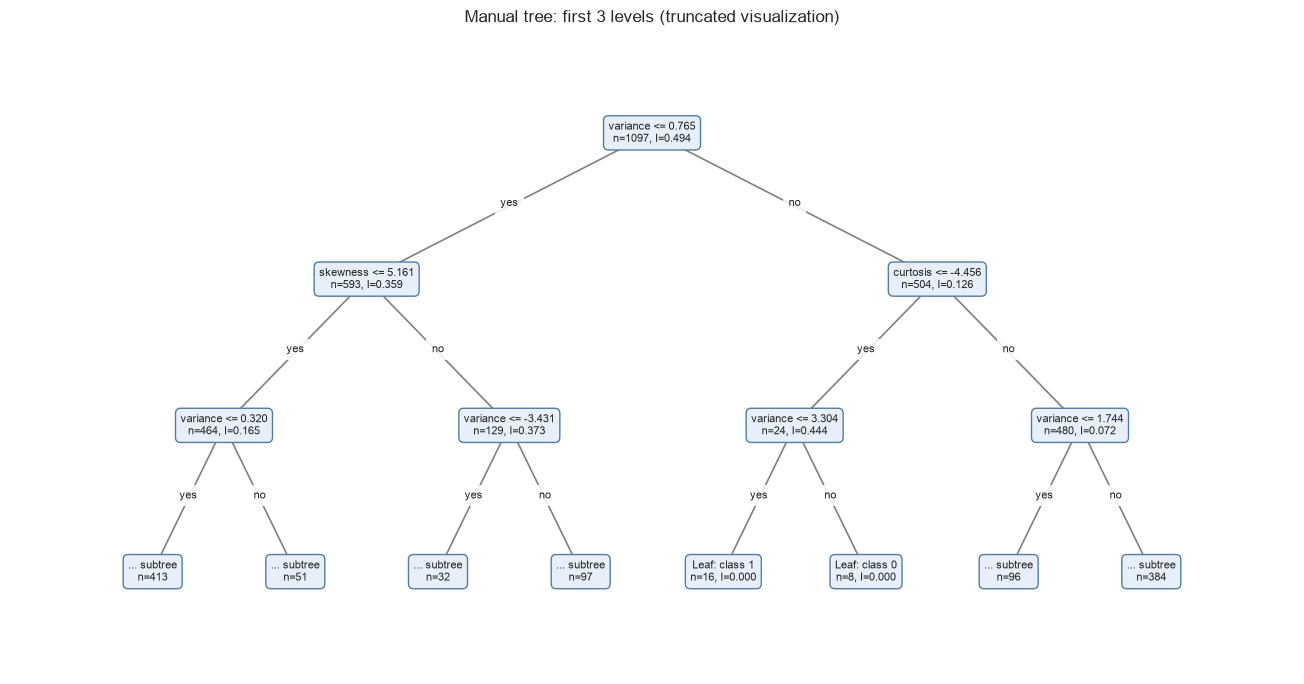

Actual manual tree rules (all nodes):
IF variance <= 0.76510 (gain=0.24209, n=1097):
  IF skewness <= 5.16080 (gain=0.14893, n=593):
    IF variance <= 0.32016 (gain=0.02869, n=464):
      IF curtosis <= 6.21865 (gain=0.00834, n=413):
        IF skewness <= 4.09405 (gain=0.00062, n=292):
          Predict 1 | n=282, impurity=0.0071, counts=(np.int64(1), np.int64(281))
        ELSE (skewness > 4.09405):
          Predict 1 | n=10, impurity=0.1800, counts=(np.int64(1), np.int64(9))
      ELSE (curtosis > 6.21865):
        IF skewness <= -3.30670 (gain=0.23689, n=121):
          Predict 1 | n=104, impurity=0.0190, counts=(np.int64(1), np.int64(103))
        ELSE (skewness > -3.30670):
          Predict 0 | n=17, impurity=0.0000, counts=(np.int64(17), np.int64(0))
    ELSE (variance > 0.32016):
      IF curtosis <= 0.47012 (gain=0.38705, n=51):
        Predict 1 | n=26, impurity=0.0000, counts=(np.int64(0), np.int64(26))
      ELSE (curtosis > 0.47012):
        IF entropy <= 0.71873 (gain=

In [11]:
def draw_manual_tree(tree, feature_names, max_display_depth=3):
    # Custom plot of the manually learned nodes (no sklearn tree used).
    positions, labels, edges = {}, {}, []
    counter = [0]
    def layout(node, depth):
        if node.is_leaf or depth >= max_display_depth:
            x = counter[0]; counter[0] += 1
        else:
            lx = layout(node.left, depth + 1)
            rx = layout(node.right, depth + 1)
            x = (lx + rx) / 2
        positions[id(node)] = (x, -depth)
        if node.is_leaf:
            text = f'Leaf: class {tree.classes_[node.prediction]}\nn={node.n_samples}, I={node.impurity:.3f}'
        elif depth >= max_display_depth:
            text = f'... subtree\nn={node.n_samples}'
        else:
            text = f'{feature_names[node.feature]} <= {node.threshold:.3f}\nn={node.n_samples}, I={node.impurity:.3f}'
            edges.extend([(node, node.left, 'yes'), (node, node.right, 'no')])
        labels[id(node)] = text
        return x
    layout(tree.root_, 0)
    fig, ax = plt.subplots(figsize=(max(12, counter[0] * 1.65), 7))
    for parent, child, edge_label in edges:
        x1, y1 = positions[id(parent)]; x2, y2 = positions[id(child)]
        ax.plot([x1, x2], [y1, y2], color='gray', lw=1.2, zorder=1)
        ax.text((x1+x2)/2, (y1+y2)/2, edge_label, fontsize=8, ha='center', bbox=dict(facecolor='white', edgecolor='none', alpha=.85))
    for node_id, (x, y_pos) in positions.items():
        ax.text(x, y_pos, labels[node_id], ha='center', va='center', fontsize=8,
                bbox=dict(boxstyle='round,pad=0.45', facecolor='#e7f0fa', edgecolor='#527da1'), zorder=2)
    ax.set_xlim(-1, max(counter[0], 2)); ax.set_ylim(-max_display_depth-.7, .7)
    ax.axis('off'); ax.set_title(f'Manual tree: first {max_display_depth} levels (truncated visualization)')
    plt.tight_layout(); plt.show()

draw_manual_tree(manual_tree, FEATURES, max_display_depth=3)
print('Actual manual tree rules (all nodes):')
manual_tree.print_rules(FEATURES)

### A13. Compare against Scikit-learn tree diagram

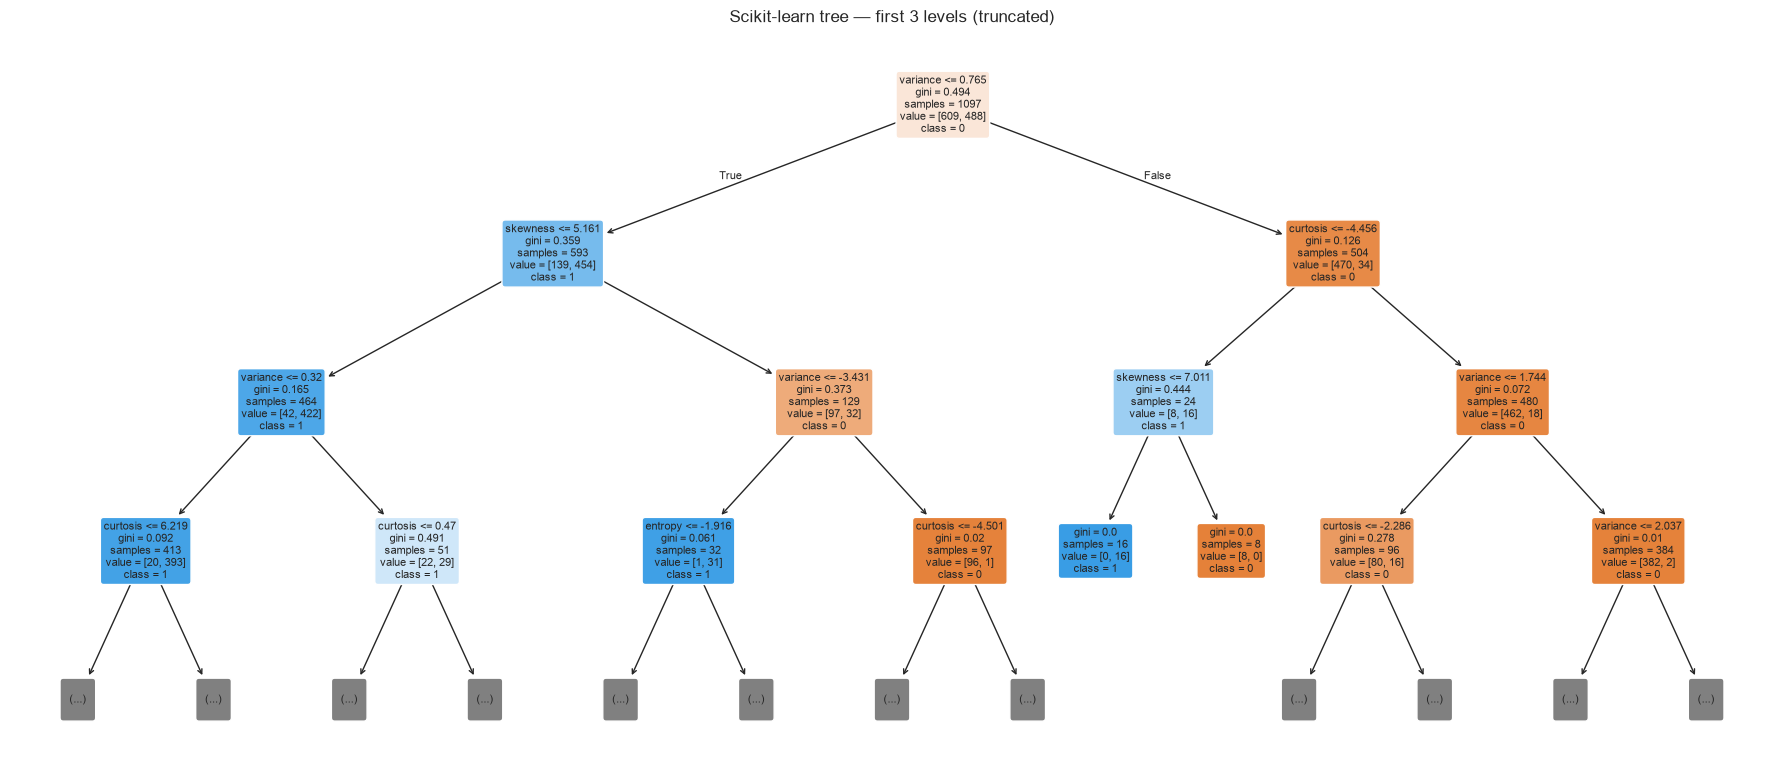

In [12]:
plt.figure(figsize=(18, 8))
plot_tree(sklearn_tree, feature_names=FEATURES, class_names=[str(c) for c in sklearn_tree.classes_],
          filled=True, rounded=True, fontsize=8, max_depth=3)
plt.title('Scikit-learn tree — first 3 levels (truncated)')
plt.tight_layout(); plt.show()

### A14. Hyperparameter experiments

Vary `criterion` and `max_depth` on identical splits. Record both training and test accuracy to diagnose overfitting. Include `None` (unrestricted depth). **Caution:** The test set is for reporting; selecting hyperparameters rigorously should use validation or cross-validation on training data, not repeated test-set tuning.

In [13]:
records = []
for crit in ['gini', 'entropy']:
    for depth in [1, 2, 3, 4, 5, 7, 10, None]:
        candidates = {
            'Manual': ManualDecisionTree(criterion=crit, max_depth=depth).fit(X_train, y_train),
            'Scikit-learn': DecisionTreeClassifier(criterion=crit, max_depth=depth, random_state=SEED).fit(X_train, y_train)
        }
        for name, model in candidates.items():
            train_pred = model.predict(X_train)
            test_pred = model.predict(X_test)
            records.append(dict(implementation=name, criterion=crit,
                                max_depth='None' if depth is None else str(depth),
                                actual_depth=model.get_depth(), leaves=model.get_n_leaves(),
                                train_accuracy=accuracy_score(y_train, train_pred),
                                test_accuracy=accuracy_score(y_test, test_pred),
                                test_f1=f1_score(y_test, test_pred, zero_division=0)))
results = pd.DataFrame(records)
display(results.round(4))

,implementation,criterion,max_depth,actual_depth,leaves,train_accuracy,test_accuracy,test_f1
0,Manual,gini,1,1,2,0.8423,0.8291,0.8278
1,Scikit-learn,gini,1,1,2,0.8423,0.8291,0.8278
2,Manual,gini,2,2,4,0.9088,0.8909,0.8780
3,Scikit-learn,gini,2,2,4,0.9088,0.8909,0.8780
4,Manual,gini,3,3,8,0.9435,0.9236,0.9176
5,Scikit-learn,gini,3,3,8,0.9435,0.9236,0.9176
6,Manual,gini,4,4,14,0.9727,0.9709,0.9683
7,Scikit-learn,gini,4,4,14,0.9727,0.9709,0.9683
8,Manual,gini,5,5,20,0.9945,0.9927,0.9919
9,Scikit-learn,gini,5,5,20,0.9945,0.9927,0.9919


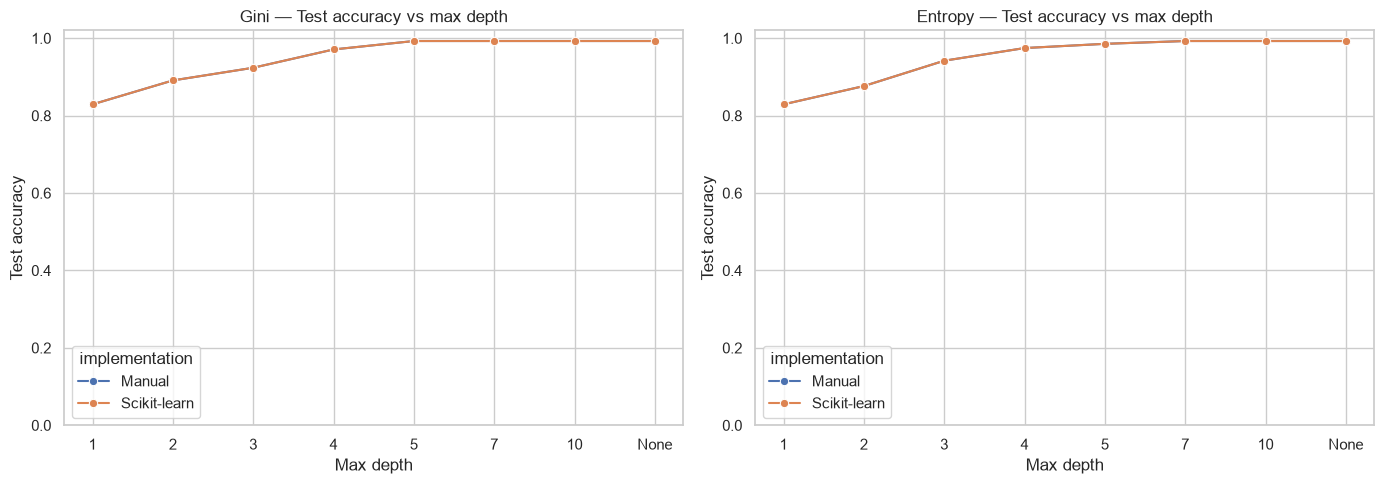

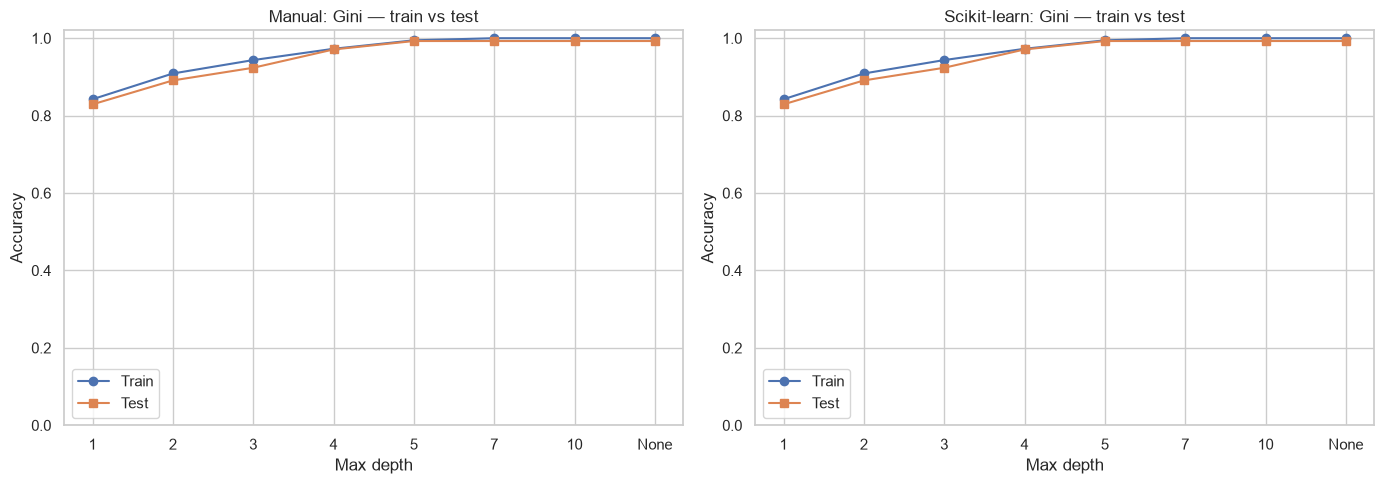

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
depth_order = ['1', '2', '3', '4', '5', '7', '10', 'None']
for ax, crit in zip(axes, ['gini', 'entropy']):
    subset = results[results.criterion == crit]
    sns.lineplot(data=subset, x='max_depth', y='test_accuracy', hue='implementation', marker='o', ax=ax,
                 sort=False)
    ax.set_xticks(range(len(depth_order)), depth_order)
    ax.set(title=f'{crit.title()} — Test accuracy vs max depth', xlabel='Max depth', ylabel='Test accuracy')
    ax.set_ylim(0, 1.02)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, impl in zip(axes, ['Manual', 'Scikit-learn']):
    sub = results[(results.implementation == impl) & (results.criterion == 'gini')]
    ax.plot(sub.max_depth, sub.train_accuracy, 'o-', label='Train')
    ax.plot(sub.max_depth, sub.test_accuracy, 's-', label='Test')
    ax.set(title=f'{impl}: Gini — train vs test', xlabel='Max depth', ylabel='Accuracy', ylim=(0, 1.02))
    ax.legend()
plt.tight_layout(); plt.show()

### A15. Prediction agreement across configurations

In [15]:
agreements = []
for crit in ['gini', 'entropy']:
    for depth in [1, 2, 3, 4, 5, 7, 10, None]:
        m = ManualDecisionTree(criterion=crit, max_depth=depth).fit(X_train, y_train)
        s = DecisionTreeClassifier(criterion=crit, max_depth=depth, random_state=SEED).fit(X_train, y_train)
        agreements.append({'criterion': crit, 'max_depth': str(depth),
                           'agreement': np.mean(m.predict(X_test) == s.predict(X_test)),
                           'manual_leaves': m.get_n_leaves(), 'sklearn_leaves': s.get_n_leaves()})
display(pd.DataFrame(agreements).round(4))

,criterion,max_depth,agreement,manual_leaves,sklearn_leaves
0,gini,1,1.0,2,2
1,gini,2,1.0,4,4
2,gini,3,1.0,8,8
3,gini,4,1.0,14,14
4,gini,5,1.0,20,20
5,gini,7,1.0,25,25
6,gini,10,1.0,25,25
7,gini,None,1.0,25,25
8,entropy,1,1.0,2,2
9,entropy,2,1.0,4,4


### A16. Findings and interpretation (auto-generated from executed results)

Interpretation should distinguish **classification performance**, **structural agreement**, and **overfitting**. The two implementations may not have identical structures because scikit-learn may permute features internally and resolve equal-gain splits differently. Avoid claiming identical trees simply from identical accuracy.

In [16]:
best_row = results.sort_values(['test_f1', 'test_accuracy'], ascending=False).iloc[0]
print(f"Highest observed test F1 (descriptive, not a valid model-selection protocol): {best_row['implementation']} | {best_row['criterion']} | depth={best_row['max_depth']} | F1={best_row['test_f1']:.4f}")
print(f'At depth 5, 4D manual and sklearn prediction agreement: {np.mean(pred_manual == pred_sklearn):.2%}')
print('For an unbiased final model comparison, select hyperparameters with a validation split/CV on training data, then evaluate the held-out test set once.')

Highest observed test F1 (descriptive, not a valid model-selection protocol): Manual | gini | depth=5 | F1=0.9919
At depth 5, 4D manual and sklearn prediction agreement: 100.00%
For an unbiased final model comparison, select hyperparameters with a validation split/CV on training data, then evaluate the held-out test set once.


# Part B — Linear Soft-Margin SVM from Scratch

**Goal:** Train a linear SVM with NumPy (no sklearn SVM in the manual fit), visualize its geometric margins and hinge-loss violations, then benchmark against `sklearn.svm.LinearSVC`.

We reuse **exactly the Part A stratified train/test indices**. Fit `StandardScaler` **only on training data** to avoid leakage; 2D and 4D experiments use separate scalers. Original class 0 becomes −1; class 1 becomes +1.

We minimize the **mean-hinge convention**

$$J(w,b)=\frac12\|w\|_2^2+C\frac1n\sum_{i=1}^n\max(0,1-y_i(w^Tx_i+b)).$$

For the violating set $V=\{i:y_i(w^Tx_i+b)<1\}$, a valid subgradient is

$$\nabla_w J=w-\frac Cn\sum_{i\in V}y_ix_i,\qquad \partial_b J=-\frac Cn\sum_{i\in V}y_i.$$

At hinge equality, choose the zero hinge subgradient. Batch subgradient descent updates $w,b$ using the **same** learning rate. The intercept is **not** regularized. A decaying schedule improves convergence for the non-smooth objective. The geometric margins are the level sets $w^Tx+b=\pm1$; the decision boundary is $w^Tx+b=0$. Violators satisfy $y_i(w^Tx_i+b)<1$ (including correctly classified points inside the margin).

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

scaler_4d = StandardScaler().fit(X_train)
X_train_svm = scaler_4d.transform(X_train)
X_test_svm = scaler_4d.transform(X_test)
scaler_2d = StandardScaler().fit(X_train_2d)
X_train_svm_2d = scaler_2d.transform(X_train_2d)
X_test_svm_2d = scaler_2d.transform(X_test_2d)
y_train_pm = np.where(y_train == 0, -1, 1)
y_test_pm = np.where(y_test == 0, -1, 1)
assert set(np.unique(y_train_pm)) == {-1, 1}
assert np.allclose(X_train_svm.mean(axis=0), 0, atol=1e-12)
assert np.allclose(X_train_svm.std(axis=0), 1, atol=1e-12)
print('4D training mean:', np.round(scaler_4d.mean_, 3))
print('4D training scale:', np.round(scaler_4d.scale_, 3))
print('Binary mapping: 0 → -1, 1 → +1')

4D training mean: [ 0.463  1.873  1.409 -1.214]
4D training scale: [2.839 5.905 4.355 2.111]
Binary mapping: 0 → -1, 1 → +1


### B1. Manual linear SVM — vectorized hinge-loss and batch subgradient descent

In [18]:
class ManualLinearSVM:
    """Minimize 0.5*||w||² + C*mean(max(0, 1-y*(X@w+b)))."""
    def __init__(self, C=1.0, learning_rate=0.05, n_iterations=4000,
                 decay=0.01, tol=0.0):
        if C <= 0 or learning_rate <= 0 or n_iterations < 1 or decay < 0:
            raise ValueError('C, learning_rate and n_iterations must be positive; decay nonnegative')
        self.C, self.learning_rate = float(C), float(learning_rate)
        self.n_iterations, self.decay, self.tol = int(n_iterations), float(decay), float(tol)

    def objective(self, X, y):
        margin = y * (X @ self.w_ + self.b_)
        return 0.5 * np.dot(self.w_, self.w_) + self.C * np.maximum(0, 1-margin).mean()

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        if X.ndim != 2 or y.shape != (len(X),) or not np.isin(y, [-1, 1]).all():
            raise ValueError('Expected X=(n_samples,n_features), labels y in {-1,+1}')
        n, d = X.shape
        self.w_ = np.zeros(d, dtype=float)
        self.b_ = 0.0
        self.history_ = []
        for t in range(self.n_iterations):
            margin = y * (X @ self.w_ + self.b_)
            violating = margin < 1.0
            grad_w = self.w_ - (self.C/n) * (X[violating].T @ y[violating])
            grad_b = -(self.C/n) * y[violating].sum()
            eta = self.learning_rate / (1.0 + self.decay * t)
            self.w_ -= eta * grad_w
            self.b_ -= eta * grad_b
            if t % 10 == 0 or t == self.n_iterations - 1:
                self.history_.append((t+1, self.objective(X, y)))
            if self.tol > 0 and np.linalg.norm(np.r_[grad_w, grad_b]) < self.tol:
                break
        self.n_iter_ = t+1
        return self

    def decision_function(self, X):
        return np.asarray(X, dtype=float) @ self.w_ + self.b_

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1).astype(int)

    def violation_mask(self, X, y):
        return np.asarray(y) * self.decision_function(X) < 1.0

    @property
    def margin_width_(self):
        norm = np.linalg.norm(self.w_)
        return 2.0/norm if norm > 0 else np.inf

# Controlled test: gradient vs finite differences away from hinge kinks
rng = np.random.default_rng(SEED)
Xt = rng.normal(size=(20, 3)); yt = rng.choice([-1, 1], size=20)
toy = ManualLinearSVM(C=0.7, learning_rate=0.02, n_iterations=30).fit(Xt, yt)
assert toy.predict(Xt).shape == (20,)
assert np.isfinite(toy.objective(Xt, yt))
print('Manual SVM unit checks passed')

Manual SVM unit checks passed


### B2. Fit and evaluate the full four-feature SVM

For a comparable objective, `LinearSVC` uses a **sum** of losses. The manual model uses their **mean**, so set `C_sklearn = C_manual / n_train`. Set `loss="hinge"` (not the default squared hinge) and `fit_intercept=True`. The intercept treatment and optimization algorithm still differ, so exact coefficient equality is not guaranteed.

,model,accuracy,precision,recall,f1
0,Manual Linear SVM (4D),0.9709,0.9385,1.0,0.9683
1,Scikit-learn LinearSVC (4D),0.9709,0.9385,1.0,0.9683


Prediction agreement: 100.00%
Manual objective: 2.76165
Manual geometric margin width (standardized units): 1.21387


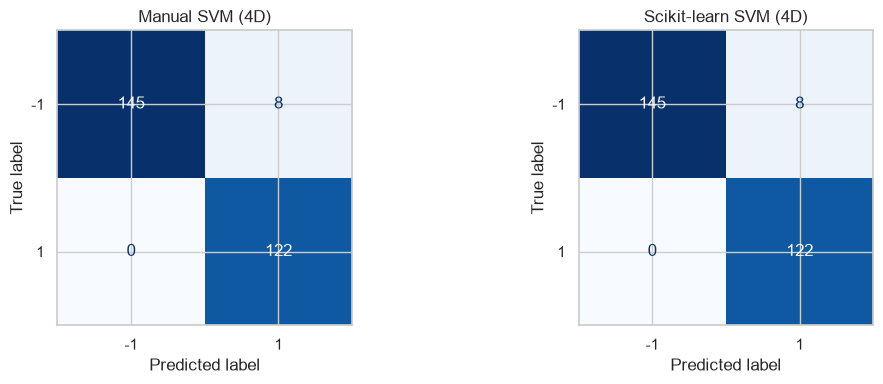

In [19]:
SVM_C = 10.0
manual_svm_4d = ManualLinearSVM(C=SVM_C, learning_rate=0.05,
                                n_iterations=5000, decay=0.002).fit(X_train_svm, y_train_pm)
sklearn_svm_4d = LinearSVC(C=SVM_C/len(y_train), loss='hinge',
                           dual=True, max_iter=30000, tol=1e-6,
                           random_state=SEED).fit(X_train_svm, y_train_pm)
svm_pred_manual_4d = manual_svm_4d.predict(X_test_svm)
svm_pred_sklearn_4d = sklearn_svm_4d.predict(X_test_svm)
svm_4d_results = pd.DataFrame([
    metric_row('Manual Linear SVM (4D)', y_test, (svm_pred_manual_4d == 1).astype(int)),
    metric_row('Scikit-learn LinearSVC (4D)', y_test, (svm_pred_sklearn_4d == 1).astype(int))
])
display(svm_4d_results.round(4))
print('Prediction agreement:', f'{np.mean(svm_pred_manual_4d == svm_pred_sklearn_4d):.2%}')
print('Manual objective:', round(manual_svm_4d.objective(X_train_svm, y_train_pm), 5))
print('Manual geometric margin width (standardized units):', round(manual_svm_4d.margin_width_, 5))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, name in zip(axes, [svm_pred_manual_4d, svm_pred_sklearn_4d],
                          ['Manual SVM (4D)', 'Scikit-learn SVM (4D)']):
    ConfusionMatrixDisplay.from_predictions(y_test_pm, pred, labels=[-1, 1],
                                            cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout(); plt.show()

### B3. Loss convergence and training diagnostics

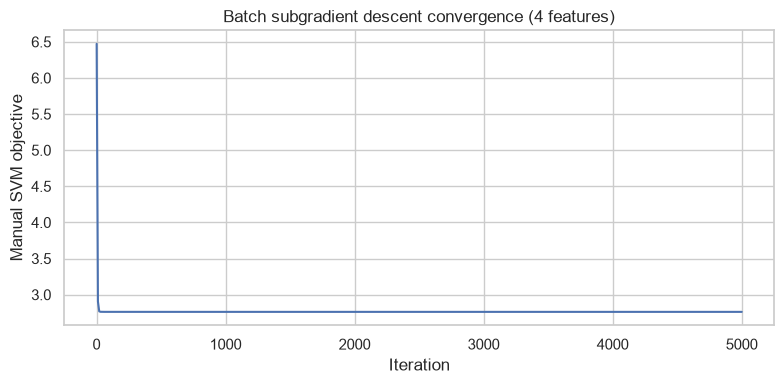

Train hinge violations: 452 / 1097
Train misclassifications: 25


In [20]:
hist = np.asarray(manual_svm_4d.history_)
plt.figure(figsize=(8, 4))
plt.plot(hist[:, 0], hist[:, 1]); plt.xlabel('Iteration'); plt.ylabel('Manual SVM objective')
plt.title('Batch subgradient descent convergence (4 features)')
plt.tight_layout(); plt.show()
print('Train hinge violations:', manual_svm_4d.violation_mask(X_train_svm, y_train_pm).sum(),
      '/', len(y_train_pm))
print('Train misclassifications:', np.sum(manual_svm_4d.predict(X_train_svm) != y_train_pm))

### B4. Fit separate two-feature SVMs and plot the separating line and margins

Plots use **standardized variance and skewness**. Each model is trained only on those two features. Orange outlined circles mark *training* examples violating the functional margin, not necessarily misclassified examples. The three parallel contours correspond to decision scores −1, 0, +1.

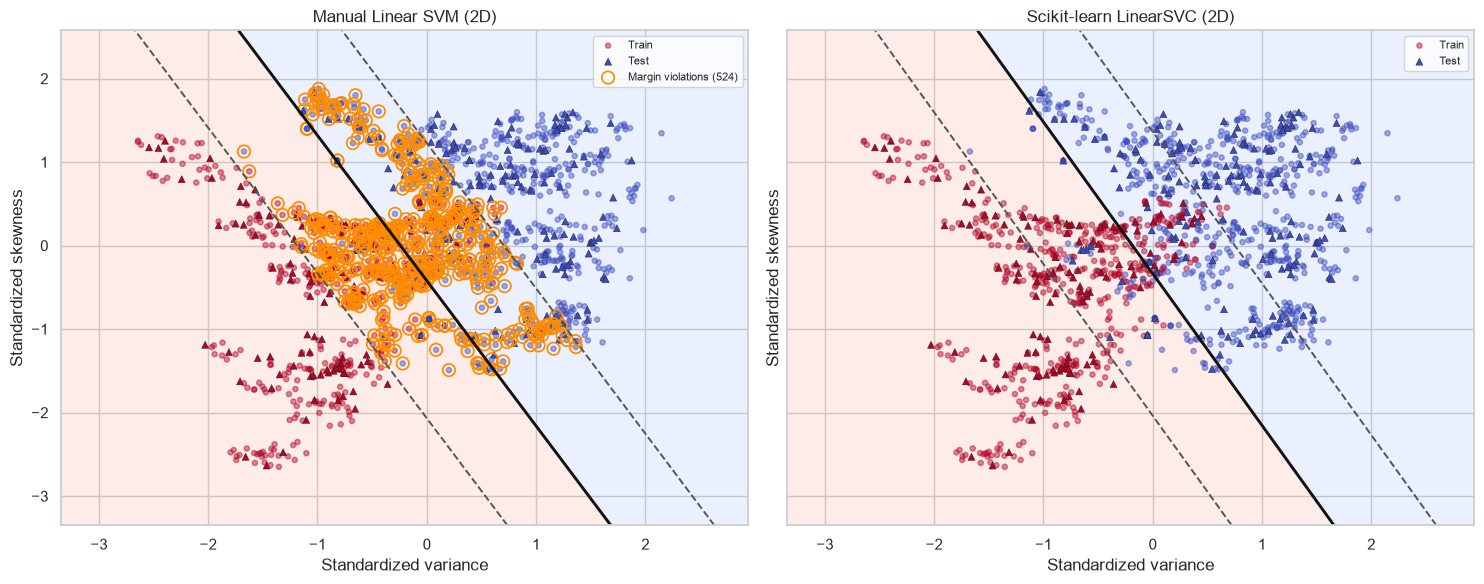

,model,accuracy,precision,recall,f1
0,Manual Linear SVM (2D),0.8873,0.8957,0.8443,0.8692
1,Scikit-learn LinearSVC (2D),0.8873,0.8824,0.8607,0.8714


In [21]:
manual_svm_2d = ManualLinearSVM(C=SVM_C, learning_rate=0.05,
                                n_iterations=5000, decay=0.002).fit(X_train_svm_2d, y_train_pm)
sklearn_svm_2d = LinearSVC(C=SVM_C/len(y_train), loss='hinge', dual=True,
                           max_iter=30000, tol=1e-6, random_state=SEED).fit(X_train_svm_2d, y_train_pm)

def plot_svm_2d(ax, model, Xtr, ytr, Xte, yte, title, show_violations=False):
    both = np.vstack((Xtr, Xte))
    xlo, ylo = both.min(axis=0) - 0.7
    xhi, yhi = both.max(axis=0) + 0.7
    xx, yy = np.meshgrid(np.linspace(xlo, xhi, 250), np.linspace(ylo, yhi, 250))
    scores = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, scores, levels=[-1e6, 0, 1e6], cmap='coolwarm', alpha=0.18)
    ax.contour(xx, yy, scores, levels=[-1, 0, 1],
               colors=['#555555', '#111111', '#555555'],
               linestyles=['--', '-', '--'], linewidths=[1.4, 2.1, 1.4])
    ax.scatter(Xtr[:, 0], Xtr[:, 1], c=ytr, cmap='coolwarm', vmin=-1, vmax=1,
               s=14, alpha=0.45, label='Train')
    ax.scatter(Xte[:, 0], Xte[:, 1], c=yte, cmap='coolwarm', vmin=-1, vmax=1,
               s=26, marker='^', edgecolor='k', linewidth=0.3, label='Test')
    if show_violations:
        bad = ytr * model.decision_function(Xtr) < 1.0
        ax.scatter(Xtr[bad, 0], Xtr[bad, 1], s=80, facecolors='none',
                   edgecolors='darkorange', linewidths=1.25,
                   label=f'Margin violations ({bad.sum()})')
    ax.set(xlabel='Standardized variance', ylabel='Standardized skewness', title=title)
    ax.legend(fontsize=8, loc='best')

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
plot_svm_2d(axes[0], manual_svm_2d, X_train_svm_2d, y_train_pm,
            X_test_svm_2d, y_test_pm, 'Manual Linear SVM (2D)', True)
plot_svm_2d(axes[1], sklearn_svm_2d, X_train_svm_2d, y_train_pm,
            X_test_svm_2d, y_test_pm, 'Scikit-learn LinearSVC (2D)')
plt.tight_layout(); plt.show()
display(pd.DataFrame([
    metric_row('Manual Linear SVM (2D)', y_test, (manual_svm_2d.predict(X_test_svm_2d) == 1).astype(int)),
    metric_row('Scikit-learn LinearSVC (2D)', y_test, (sklearn_svm_2d.predict(X_test_svm_2d) == 1).astype(int))
]).round(4))

### B5. Regularization study — vary C

Larger C places greater weight on hinge violations, typically fitting training data more tightly at the expense of a smaller margin. This is a tendency, not a guarantee of monotonic test accuracy. Report the actual results.

,C,model,accuracy,f1,margin_width,train_violations
0,0.1,Manual,0.5600,0.0163,23.4382,1097
1,0.1,Scikit-learn,0.8618,0.8430,23.4382,1097
2,1.0,Manual,0.8836,0.8571,3.4726,934
3,1.0,Scikit-learn,0.8909,0.8760,3.3389,967
4,10.0,Manual,0.9709,0.9683,1.2139,451
5,10.0,Scikit-learn,0.9709,0.9683,1.2158,454
6,100.0,Manual,0.9709,0.9683,0.7021,155
7,100.0,Scikit-learn,0.9709,0.9683,0.7095,152


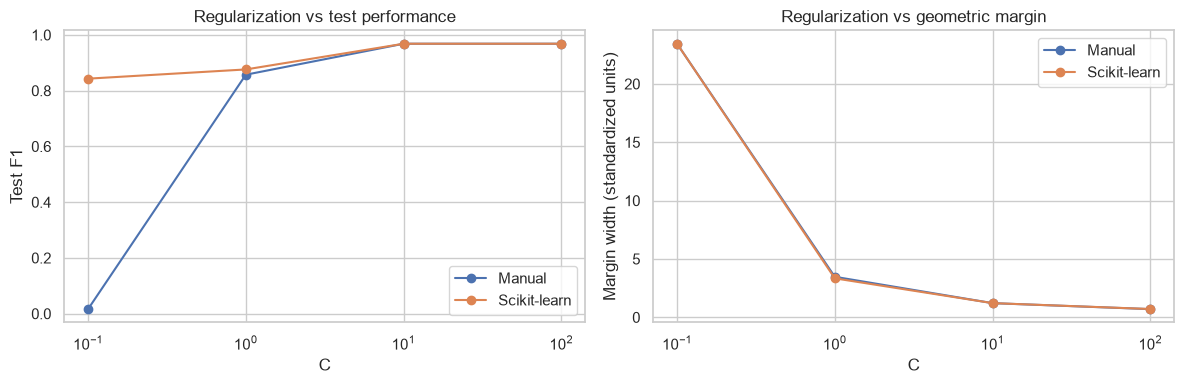

In [22]:
c_rows = []
for c in [0.1, 1.0, 10.0, 100.0]:
    m = ManualLinearSVM(C=c, learning_rate=0.03, n_iterations=4000, decay=0.003).fit(X_train_svm, y_train_pm)
    sk = LinearSVC(C=c/len(y_train), loss='hinge', dual=True,
                   max_iter=30000, tol=1e-6, random_state=SEED).fit(X_train_svm, y_train_pm)
    for name, model in [('Manual', m), ('Scikit-learn', sk)]:
        pred = model.predict(X_test_svm)
        w = m.w_ if name == 'Manual' else sk.coef_.ravel()
        c_rows.append({'C': c, 'model': name, 'accuracy': accuracy_score(y_test_pm, pred),
                       'f1': f1_score(y_test_pm, pred, pos_label=1),
                       'margin_width': 2/np.linalg.norm(w),
                       'train_violations': int(np.sum(y_train_pm * model.decision_function(X_train_svm) < 1))})
c_results = pd.DataFrame(c_rows)
display(c_results.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, sub in c_results.groupby('model'):
    axes[0].plot(sub['C'], sub['f1'], marker='o', label=name)
    axes[1].plot(sub['C'], sub['margin_width'], marker='o', label=name)
for ax in axes: ax.set_xscale('log'); ax.set_xlabel('C'); ax.legend()
axes[0].set(ylabel='Test F1', title='Regularization vs test performance')
axes[1].set(ylabel='Margin width (standardized units)', title='Regularization vs geometric margin')
plt.tight_layout(); plt.show()

### B6. Optimization study — learning rate and iteration budget

Keep C fixed while varying one optimization parameter at a time. These are optimizer settings, not SVM regularization parameters. Objective and test metrics may fluctuate because hinge loss is nonsmooth.

,learning_rate,iterations,train_objective,test_accuracy,test_f1
0,0.005,200,2.78682,0.96364,0.96000
1,0.005,1000,2.76165,0.97091,0.96825
2,0.005,4000,2.76165,0.97091,0.96825
3,0.020,200,2.76166,0.97091,0.96825
4,0.020,1000,2.76165,0.97091,0.96825
5,0.020,4000,2.76165,0.97091,0.96825
6,0.100,200,2.76722,0.97091,0.96825
7,0.100,1000,2.76169,0.97091,0.96825
8,0.100,4000,2.76166,0.97091,0.96825


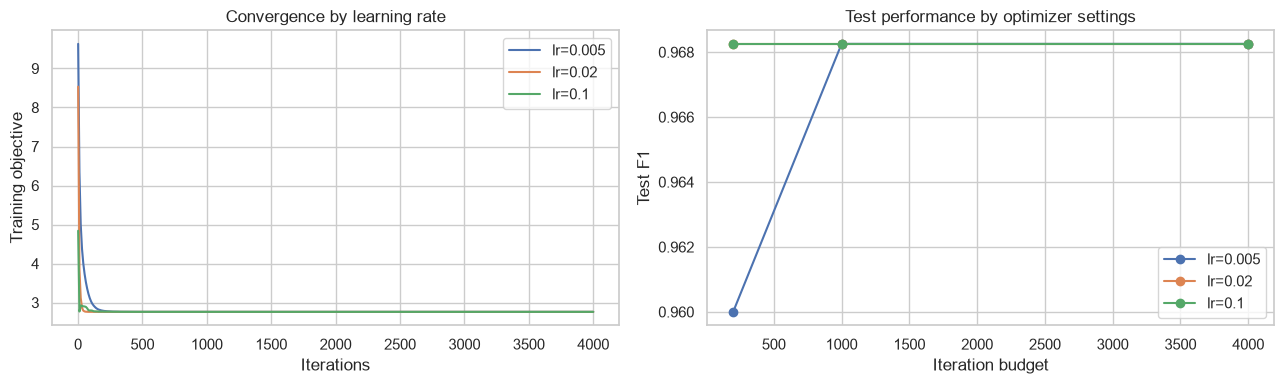

In [23]:
optimization_rows = []
optimization_histories = {}
for lr in [0.005, 0.02, 0.1]:
    for steps in [200, 1000, 4000]:
        m = ManualLinearSVM(C=10, learning_rate=lr, n_iterations=steps, decay=0.002).fit(X_train_svm, y_train_pm)
        pred = m.predict(X_test_svm)
        optimization_rows.append({'learning_rate': lr, 'iterations': steps,
                                  'train_objective': m.objective(X_train_svm, y_train_pm),
                                  'test_accuracy': accuracy_score(y_test_pm, pred),
                                  'test_f1': f1_score(y_test_pm, pred, pos_label=1)})
        optimization_histories[(lr, steps)] = np.asarray(m.history_)
optimization_results = pd.DataFrame(optimization_rows)
display(optimization_results.round(5))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for lr in [0.005, 0.02, 0.1]:
    hist = optimization_histories[(lr, 4000)]
    axes[0].plot(hist[:, 0], hist[:, 1], label=f'lr={lr}')
    sub = optimization_results[optimization_results.learning_rate == lr]
    axes[1].plot(sub.iterations, sub.test_f1, marker='o', label=f'lr={lr}')
axes[0].set(xlabel='Iterations', ylabel='Training objective', title='Convergence by learning rate')
axes[1].set(xlabel='Iteration budget', ylabel='Test F1', title='Test performance by optimizer settings')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

### B7. Results and interpretation

Use the four-feature models for headline performance; the two-feature models are for faithful 2D geometry. The evaluation set should ideally be held out for final assessment; hyperparameter selection in a real application should use a validation split or cross-validation **inside training data**, rather than selecting based on test metrics.

In [24]:
best_c = c_results[c_results.model == 'Manual'].sort_values('f1', ascending=False).iloc[0]
best_optim = optimization_results.sort_values(['test_f1', 'train_objective'], ascending=[False, True]).iloc[0]
print('Manual vs sklearn (4D):')
display(svm_4d_results.round(4))
print(f'Highest observed manual test F1 in C sweep: C={best_c.C:g}, F1={best_c.f1:.4f}')
print(f'Highest observed manual test F1 in optimizer sweep: lr={best_optim.learning_rate:g}, '
      f'iterations={int(best_optim.iterations)}, F1={best_optim.test_f1:.4f}')
print('Note: sweeps use the held-out test set for assignment exploration only; do not use these '
      'results as an unbiased estimate after selecting hyperparameters.')
print('2D manual train margin violations:', int(manual_svm_2d.violation_mask(X_train_svm_2d, y_train_pm).sum()))
print('Part B complete.')

Manual vs sklearn (4D):


,model,accuracy,precision,recall,f1
0,Manual Linear SVM (4D),0.9709,0.9385,1.0,0.9683
1,Scikit-learn LinearSVC (4D),0.9709,0.9385,1.0,0.9683


Highest observed manual test F1 in C sweep: C=100, F1=0.9683
Highest observed manual test F1 in optimizer sweep: lr=0.005, iterations=4000, F1=0.9683
Note: sweeps use the held-out test set for assignment exploration only; do not use these results as an unbiased estimate after selecting hyperparameters.
2D manual train margin violations: 524
Part B complete.


# Part C — Kernel SVM and Nonlinear Decision Boundaries

**Goal:** Demonstrate why a nonlinear kernel can classify data that a linear separating hyperplane cannot.

This section uses a separate **synthetic 2D dataset** generated with `make_moons`, not the banknote dataset. It compares three **Scikit-learn** SVM classifiers on identical train/test splits:

1. **Linear:** \(K(x,z)=x^\top z\)
2. **Polynomial (degree 3):** \(K(x,z)=(\gamma x^\top z+r)^3\)
3. **RBF:** \(K(x,z)=\exp(-\gamma\|x-z\|^2)\)

The kernel trick allows the SVM to calculate inner products in an implicit feature space without explicitly constructing that space. A nonlinear decision boundary in the original 2D input space can then emerge from a linear separator in the implicit feature space.

**Fair comparison:** Standardize features using *training data only*, use the same split and `C=1` for each kernel, and report held-out test metrics. `gamma='scale'` and `coef0=1` are used for polynomial/RBF configuration as applicable.


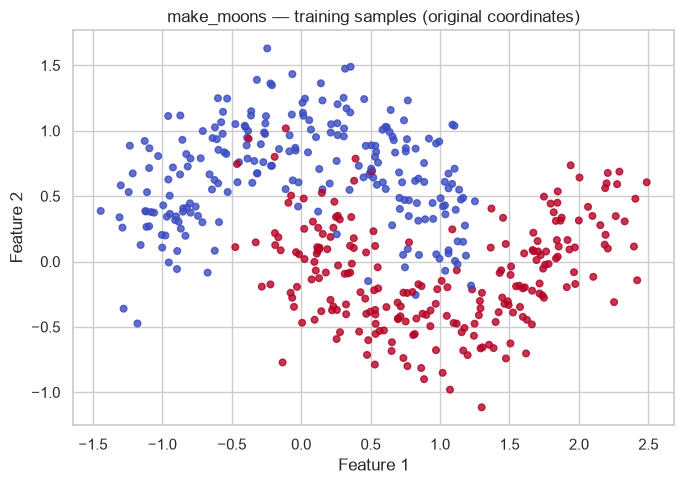

Train: (450, 2) | Test: (150, 2)


In [25]:
# C1. Generate and visualize the nonlinear dataset
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

X_moons, y_moons = make_moons(n_samples=600, noise=0.23, random_state=42)
X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons, y_moons, test_size=0.25, random_state=42, stratify=y_moons
)
moon_scaler = StandardScaler().fit(X_moons_train)
X_moons_train_scaled = moon_scaler.transform(X_moons_train)
X_moons_test_scaled = moon_scaler.transform(X_moons_test)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_moons_train[:, 0], X_moons_train[:, 1],
           c=y_moons_train, cmap='coolwarm', s=23, alpha=0.8)
ax.set(xlabel='Feature 1', ylabel='Feature 2', title='make_moons — training samples (original coordinates)')
plt.tight_layout()
plt.show()
print('Train:', X_moons_train.shape, '| Test:', X_moons_test.shape)


In [26]:
# C2. Train linear, polynomial, and RBF SVMs with identical training data
kernel_specs = {
    'Linear': {'kernel': 'linear', 'C': 1.0},
    'Polynomial (degree 3)': {'kernel': 'poly', 'degree': 3, 'gamma': 'scale', 'coef0': 1.0, 'C': 1.0},
    'RBF': {'kernel': 'rbf', 'gamma': 'scale', 'C': 1.0},
}
kernel_models = {}
kernel_metrics = []
for name, params in kernel_specs.items():
    model = SVC(**params)
    model.fit(X_moons_train_scaled, y_moons_train)
    kernel_models[name] = model
    predictions = model.predict(X_moons_test_scaled)
    kernel_metrics.append({
        'Kernel': name,
        'Train accuracy': accuracy_score(y_moons_train, model.predict(X_moons_train_scaled)),
        'Test accuracy': accuracy_score(y_moons_test, predictions),
        'Precision': precision_score(y_moons_test, predictions, zero_division=0),
        'Recall': recall_score(y_moons_test, predictions, zero_division=0),
        'F1': f1_score(y_moons_test, predictions, zero_division=0),
        'Support vectors': len(model.support_),
    })
kernel_results = pd.DataFrame(kernel_metrics)
print(kernel_results.round(4).to_string(index=False))


               Kernel  Train accuracy  Test accuracy  Precision  Recall     F1  Support vectors
               Linear          0.8644         0.8733     0.8500  0.9067 0.8774              148
Polynomial (degree 3)          0.9244         0.9267     0.9103  0.9467 0.9281               98
                  RBF          0.9311         0.9333     0.9114  0.9600 0.9351              112


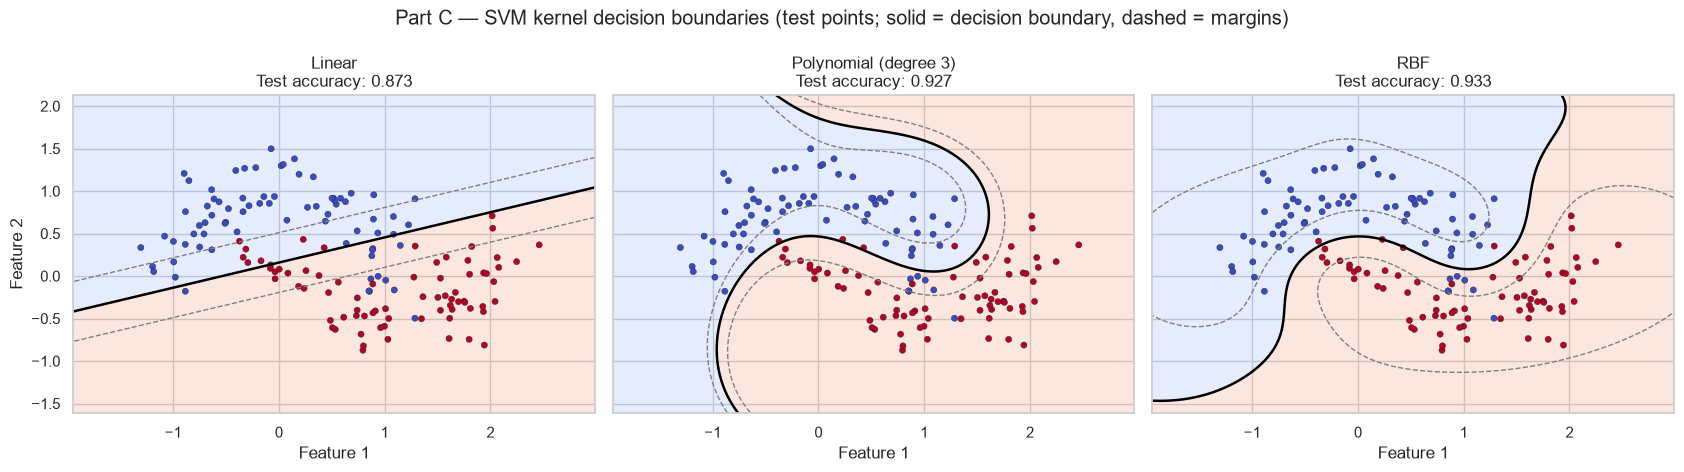

In [27]:
# C3. Side-by-side decision boundaries in ORIGINAL feature coordinates
# The fitted scaler transforms the plotting grid before model inference.
x_min, x_max = X_moons[:, 0].min() - 0.5, X_moons[:, 0].max() + 0.5
y_min, y_max = X_moons[:, 1].min() - 0.5, X_moons[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 350),
                     np.linspace(y_min, y_max, 350))
grid_original = np.c_[xx.ravel(), yy.ravel()]
grid_scaled = moon_scaler.transform(grid_original)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharex=True, sharey=True)
for ax, (name, model) in zip(axes, kernel_models.items()):
    scores = model.decision_function(grid_scaled).reshape(xx.shape)
    ax.contourf(xx, yy, scores > 0, levels=[-0.5, 0.5, 1.5],
                cmap='coolwarm', alpha=0.23)
    ax.contour(xx, yy, scores, levels=[-1, 0, 1],
               colors=['gray', 'black', 'gray'],
               linestyles=['--', '-', '--'], linewidths=[1, 1.8, 1])
    ax.scatter(X_moons_test[:, 0], X_moons_test[:, 1], c=y_moons_test,
               cmap='coolwarm', s=20, edgecolors='k', linewidths=0.25)
    ax.set_title(f'{name}\nTest accuracy: {accuracy_score(y_moons_test, model.predict(X_moons_test_scaled)):.3f}')
    ax.set_xlabel('Feature 1')
axes[0].set_ylabel('Feature 2')
fig.suptitle('Part C — SVM kernel decision boundaries (test points; solid = decision boundary, dashed = margins)')
plt.tight_layout()
plt.show()


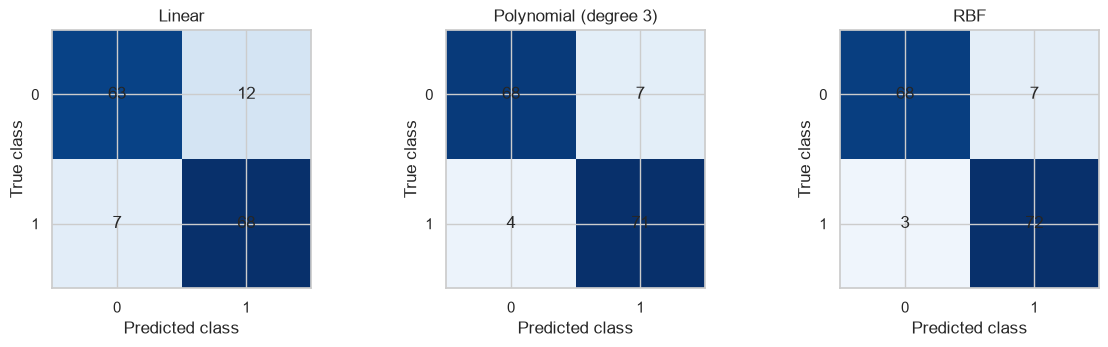

In [28]:
# C4. Confusion matrices for held-out test samples
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (name, model) in zip(axes, kernel_models.items()):
    cm = confusion_matrix(y_moons_test, model.predict(X_moons_test_scaled), labels=[0, 1])
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=max(1, cm.max()))
    for (i, j), count in np.ndenumerate(cm):
        ax.text(j, i, str(count), ha='center', va='center', fontsize=12)
    ax.set(title=name, xlabel='Predicted class', ylabel='True class',
           xticks=[0, 1], yticks=[0, 1])
plt.tight_layout()
plt.show()


### C5. Interpretation and conclusions

- **Linear kernel:** Its separating boundary is a straight line in the original two-dimensional feature space, so it may underfit the curved, interleaving moon shapes.
- **Polynomial kernel:** Uses polynomial similarities to produce a curved boundary; its flexibility depends on degree, `C`, `gamma`, and `coef0`.
- **RBF kernel:** Measures similarity based on distance and can form locally curved boundaries, often making it effective for the two-moons pattern.
- **Kernel trick:** Instead of explicitly generating many transformed features, the algorithm evaluates the kernel \(K(x_i,x_j)\), which acts like a dot product in a possibly high-dimensional feature space. Kernel methods are **not automatically computationally cheaper overall**: kernel matrices and optimization can become expensive for large datasets.
- **Margins:** The solid contour is the score-zero separating boundary. Dashed contours mark decision-function scores of \(-1\) and \(+1\). Support vectors and the resulting margins depend on the fitted model.
- **Evaluation:** Compare **test accuracy and F1**, not training accuracy alone. The best kernel can change with the data, noise, and hyperparameters. These results are for a synthetic dataset, not the banknote dataset.


# Part D — Final Comparison on the Original Banknote Dataset

This final experiment compares **five classifiers** on the **same original four-feature dataset and exactly the same stratified 80/20 train/test split** created in Part A (`X_train`, `X_test`, `y_train`, `y_test`).

| Model | Features | Preprocessing |
|---|---|---|
| Manual Decision Tree | All 4 | Raw features |
| Scikit-learn Decision Tree | All 4 | Raw features |
| Manual Linear SVM | All 4 | Training-set standardization |
| Scikit-learn Linear SVM | All 4 | Same training-set standardization |
| Scikit-learn RBF SVM | All 4 | Same training-set standardization |

**Timing methodology:** Fit and prediction times are measured independently with `time.perf_counter()`. Scaling is fitted once on training data outside the model timers so the reported model timings are comparable; report preprocessing separately. Timing varies by computer and run. Manual SVM uses label values `-1/+1`, and predictions are mapped back to `0/1` for identical scoring.

**Objective consistency:** Manual SVM minimizes \( \frac12\|w\|^2 + C_{\mathrm{manual}}\operatorname{mean}(\mathrm{hinge}) \). Scikit-learn `LinearSVC` minimizes \( \frac12\|w\|^2 + C_{\mathrm{sklearn}}\operatorname{sum}(\mathrm{hinge}) \). Therefore use \(C_{\mathrm{sklearn}}=C_{\mathrm{manual}}/n_{\mathrm{train}}\) when comparing these objectives.


In [29]:
# D1. Verify the shared split and prepare scaled features without data leakage
from time import perf_counter
from sklearn.svm import SVC, LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

assert X_train.shape[1] == X_test.shape[1] == 4
assert len(X_train) + len(X_test) == 1372
assert np.array_equal(np.unique(y_train), [0, 1])
assert np.array_equal(np.unique(y_test), [0, 1])
assert not np.shares_memory(X_train, X_test)

start_preprocessing = perf_counter()
final_scaler = StandardScaler().fit(X_train)
X_train_scaled_final = final_scaler.transform(X_train)
X_test_scaled_final = final_scaler.transform(X_test)
scaling_time_s = perf_counter() - start_preprocessing
y_train_signed_final = np.where(y_train == 0, -1, 1)
print('Shared split:', len(y_train), 'training /', len(y_test), 'testing samples')
print('Features:', FEATURES)
print(f'Training-only scaling (fit + both transforms): {scaling_time_s:.6f} seconds')


Shared split: 1097 training / 275 testing samples
Features: ['variance', 'skewness', 'curtosis', 'entropy']
Training-only scaling (fit + both transforms): 0.001771 seconds


In [30]:
# D2. Fit and benchmark all five models
# The C adjustment makes the linear SVM objectives comparable.
D_TREE_DEPTH = 5
D_TREE_CRITERION = 'gini'
D_MANUAL_C = 10.0
D_LINEAR_SK_C = D_MANUAL_C / len(y_train)
D_RBF_C = 1.0

final_model_specs = [
    ('Manual Decision Tree',
     ManualDecisionTree(criterion=D_TREE_CRITERION, max_depth=D_TREE_DEPTH),
     X_train, X_test, y_train, False),
    ('Scikit-learn Decision Tree',
     DecisionTreeClassifier(criterion=D_TREE_CRITERION, max_depth=D_TREE_DEPTH, random_state=SEED),
     X_train, X_test, y_train, False),
    ('Manual Linear SVM',
     ManualLinearSVM(C=D_MANUAL_C, learning_rate=0.05, n_iterations=5000, decay=0.002),
     X_train_scaled_final, X_test_scaled_final, y_train_signed_final, True),
    ('Scikit-learn Linear SVM',
     LinearSVC(C=D_LINEAR_SK_C, loss='hinge', dual=True,
               max_iter=30000, tol=1e-6, random_state=SEED),
     X_train_scaled_final, X_test_scaled_final, y_train_signed_final, True),
    ('Scikit-learn RBF SVM',
     SVC(kernel='rbf', C=D_RBF_C, gamma='scale'),
     X_train_scaled_final, X_test_scaled_final, y_train, False),
]

final_models = {}
final_predictions = {}
final_rows = []
for name, model, train_features, test_features, train_labels, signed_labels in final_model_specs:
    t0 = perf_counter()
    model.fit(train_features, train_labels)
    fit_seconds = perf_counter() - t0

    t0 = perf_counter()
    predicted = model.predict(test_features)
    predict_seconds = perf_counter() - t0

    if signed_labels:
        predicted = (np.asarray(predicted) == 1).astype(int)
    else:
        predicted = np.asarray(predicted, dtype=int)

    assert predicted.shape == y_test.shape
    final_models[name] = model
    final_predictions[name] = predicted
    final_rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predicted),
        'Precision': precision_score(y_test, predicted, zero_division=0),
        'Recall': recall_score(y_test, predicted, zero_division=0),
        'F1-score': f1_score(y_test, predicted, zero_division=0),
        'Train time (s)': fit_seconds,
        'Predict time (s)': predict_seconds,
    })

final_results = pd.DataFrame(final_rows)
display(final_results.round(5))


,Model,Accuracy,Precision,Recall,F1-score,Train time (s),Predict time (s)
0,Manual Decision Tree,0.99273,0.98387,1.0,0.99187,0.78183,0.00020
1,Scikit-learn Decision Tree,0.99273,0.98387,1.0,0.99187,0.00210,0.00016
2,Manual Linear SVM,0.97091,0.93846,1.0,0.96825,0.15507,0.00002
3,Scikit-learn Linear SVM,0.97091,0.93846,1.0,0.96825,0.00111,0.00019
4,Scikit-learn RBF SVM,1.00000,1.00000,1.0,1.00000,0.00384,0.00142


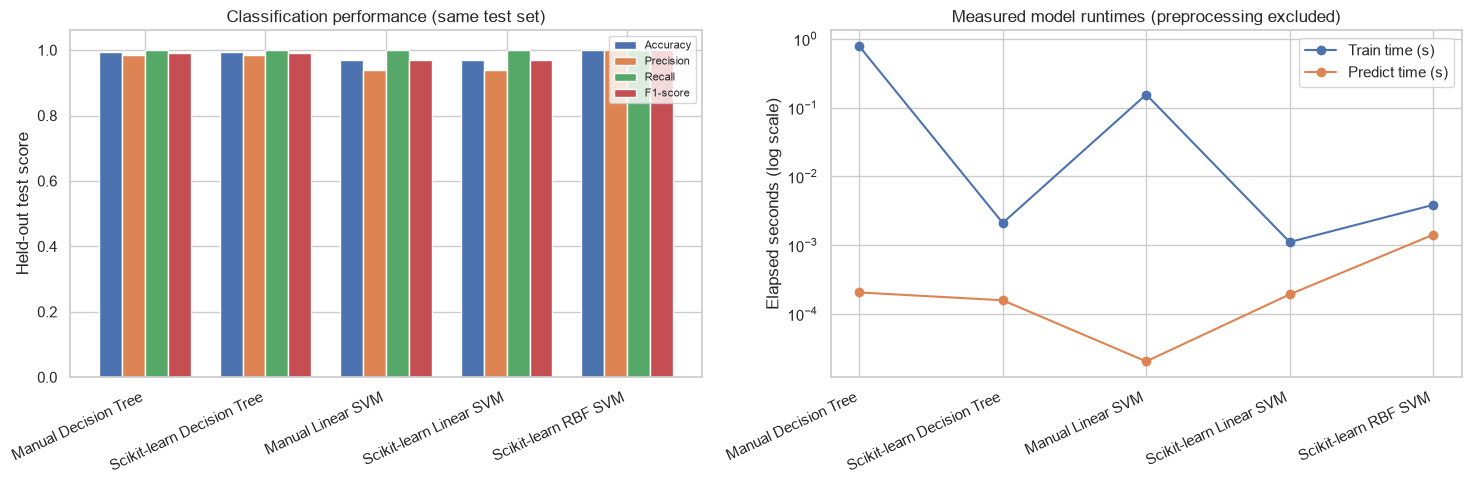

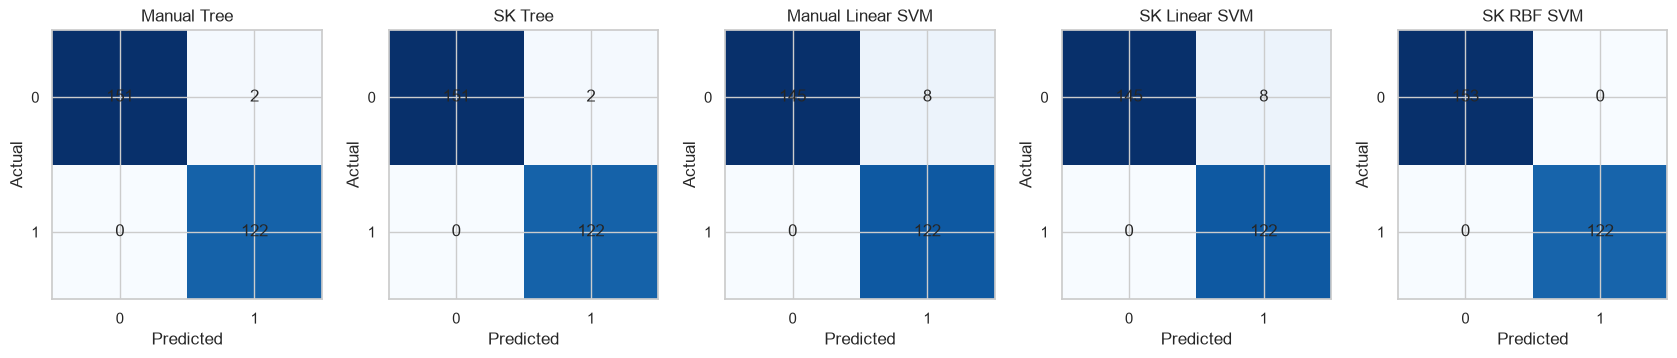

In [31]:
# D3. Compare performance, model runtimes, and confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
names = final_results['Model'].tolist()
positions = np.arange(len(names))
width = 0.19
for j, metric in enumerate(['Accuracy', 'Precision', 'Recall', 'F1-score']):
    axes[0].bar(positions + (j - 1.5) * width, final_results[metric],
                width=width, label=metric)
axes[0].set_xticks(positions, names, rotation=25, ha='right')
axes[0].set_ylim(0, 1.06)
axes[0].set_ylabel('Held-out test score')
axes[0].set_title('Classification performance (same test set)')
axes[0].legend(fontsize=8)

for metric in ['Train time (s)', 'Predict time (s)']:
    axes[1].plot(positions, final_results[metric], marker='o', label=metric)
axes[1].set_xticks(positions, names, rotation=25, ha='right')
axes[1].set_ylabel('Elapsed seconds (log scale)')
axes[1].set_yscale('log')
axes[1].set_title('Measured model runtimes (preprocessing excluded)')
axes[1].legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 5, figsize=(17, 3.4))
for ax, (name, pred) in zip(axes, final_predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=max(1, cm.max()))
    for (i, j), count in np.ndenumerate(cm):
        ax.text(j, i, str(count), ha='center', va='center')
    ax.set(title=name.replace('Scikit-learn ', 'SK ').replace('Decision Tree', 'Tree'),
           xlabel='Predicted', ylabel='Actual', xticks=[0, 1], yticks=[0, 1])
plt.tight_layout()
plt.show()


In [32]:
# D4. Generalization gaps and basic complexity diagnostics
generalization_rows = []
for name, model, train_features, _, train_labels, signed_labels in final_model_specs:
    train_pred = model.predict(train_features)
    if signed_labels:
        train_pred = (np.asarray(train_pred) == 1).astype(int)
    train_accuracy = accuracy_score(y_train, train_pred)
    test_accuracy = accuracy_score(y_test, final_predictions[name])
    if name == 'Manual Decision Tree':
        complexity = f"depth={model.get_depth()}, leaves={model.get_n_leaves()}"
    elif name == 'Scikit-learn Decision Tree':
        complexity = f"depth={model.get_depth()}, leaves={model.get_n_leaves()}"
    elif name == 'Manual Linear SVM':
        complexity = f"{len(model.w_)} weights; iterations={model.n_iter_}"
    elif name == 'Scikit-learn Linear SVM':
        complexity = f"{model.coef_.size} weights; iterations={model.n_iter_}"
    else:
        complexity = f"support vectors={len(model.support_)}"
    generalization_rows.append({
        'Model': name, 'Train accuracy': train_accuracy,
        'Test accuracy': test_accuracy,
        'Train-test gap': train_accuracy - test_accuracy,
        'Complexity indicator': complexity,
    })
generalization_results = pd.DataFrame(generalization_rows)
display(generalization_results.round(4))
print('Manual vs sklearn tree agreement:',
      f"{np.mean(final_predictions['Manual Decision Tree'] == final_predictions['Scikit-learn Decision Tree']):.2%}")
print('Manual vs sklearn linear SVM agreement:',
      f"{np.mean(final_predictions['Manual Linear SVM'] == final_predictions['Scikit-learn Linear SVM']):.2%}")


,Model,Train accuracy,Test accuracy,Train-test gap,Complexity indicator
0,Manual Decision Tree,0.9945,0.9927,0.0018,"depth=5, leaves=20"
1,Scikit-learn Decision Tree,0.9945,0.9927,0.0018,"depth=5, leaves=20"
2,Manual Linear SVM,0.9772,0.9709,0.0063,4 weights; iterations=5000
3,Scikit-learn Linear SVM,0.9781,0.9709,0.0072,4 weights; iterations=91
4,Scikit-learn RBF SVM,1.0000,1.0000,0.0000,support vectors=91


Manual vs sklearn tree agreement: 100.00%
Manual vs sklearn linear SVM agreement: 100.00%


### D5. Discussion: interpretability, scaling, overfitting, complexity

**Interpretability**
- Decision Trees provide human-readable if/else split rules, feature thresholds, and leaf decisions. Shallow trees are easier to explain; deep trees become cumbersome.
- Linear SVMs produce feature weights and an intercept, so feature effects can be inspected in **standardized feature units**. Coefficient size alone does not establish causality.
- RBF SVM predictions depend on nonlinear similarities to support vectors; they are generally less interpretable than shallow trees or linear SVMs.

**Scaling**
- Decision Trees use ordering/thresholds and generally do not require standardization.
- Both linear and RBF SVMs are sensitive to feature scale. Fit the scaler **only on training data**, then reuse it for test data. Scaling is excluded from the model-only runtime measurements above.

**Overfitting and generalization**
- Increasing tree depth may improve training accuracy while reducing test accuracy. Compare the train-test gaps above.
- Linear SVM `C` controls the penalty for hinge violations; larger `C` can reduce regularization and may increase sensitivity to noise.
- RBF SVM `C` and `gamma` control boundary flexibility; large `gamma` can create localized boundaries that overfit.
- Test-set scores should be used for **final reporting**, not repeatedly optimized against. For hyperparameter selection, use training-only cross-validation.

**Model complexity and computation**
- A Decision Tree can make predictions through a short sequence of feature comparisons; a full tree may have many nodes and its greedy fitting cost depends on split search.
- A linear SVM uses a weight vector of length four and a bias, making inference inexpensive.
- An RBF SVM stores support vectors and typically evaluates kernel similarities to them at inference; runtime and memory can grow with their count.
- The NumPy manual implementations are educational and are not expected to match the optimized Scikit-learn implementations in runtime.
- Timings are one-run measurements and include Python overhead; repeat runs and report median timings if rigorous runtime comparisons are required.

### D6. Final conclusions (automatically derived from the executed comparison)


In [33]:
# D6. Report observed results rather than assuming which model wins
winner = final_results.sort_values(['F1-score', 'Accuracy'], ascending=False).iloc[0]
fastest_fit = final_results.loc[final_results['Train time (s)'].idxmin()]
fastest_predict = final_results.loc[final_results['Predict time (s)'].idxmin()]
print(f"Highest test F1: {winner['Model']} (F1={winner['F1-score']:.4f}, accuracy={winner['Accuracy']:.4f})")
print(f"Fastest measured training: {fastest_fit['Model']} ({fastest_fit['Train time (s)']:.6f} s)")
print(f"Fastest measured prediction: {fastest_predict['Model']} ({fastest_predict['Predict time (s)']:.6f} s)")
print('\nAll results use the original Banknote dataset, all four features, and the same held-out test set.')
print('Runtime results are machine-dependent and exclude scaling.')
print('Use the comparison tables above to support the final GitHub README discussion.')


Highest test F1: Scikit-learn RBF SVM (F1=1.0000, accuracy=1.0000)
Fastest measured training: Scikit-learn Linear SVM (0.001107 s)
Fastest measured prediction: Manual Linear SVM (0.000020 s)

All results use the original Banknote dataset, all four features, and the same held-out test set.
Runtime results are machine-dependent and exclude scaling.
Use the comparison tables above to support the final GitHub README discussion.
